In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
import os
import numpy as np
import pickle
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping


2025-07-25 04:49:27.796729: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753418968.022536      35 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753418968.135034      35 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
def load_pickle(file_path):
    with open(file_path, 'rb') as f:
        return pickle.load(f)

# Load all data-label pairs
def load_dataset(data_dir, label_dir):
    X, Y = [], []
    for filename in os.listdir(data_dir):
        
        data_path = os.path.join(data_dir, filename)
        label_fn = filename[0:-8] + "label.pkl"
        # print(label_fn)
        label_path = os.path.join(label_dir, label_fn)
        
        if os.path.exists(label_path):
            signal = load_pickle(data_path)
            signal = np.array(signal).astype(np.float32)

            label = load_pickle(label_path)
            label = np.array(label).astype(np.uint8)

            # Reshape and one-hot encode
            signal = signal.reshape(-1, 1)  # shape: (60000, 1)
            label = tf.keras.utils.to_categorical(label, num_classes=3)  # shape: (60000, 3)

            X.append(signal)
            Y.append(label)
        else:
            print("file not found")
    return np.array(X), np.array(Y)

In [4]:
# Load full dataset
data_path = "/kaggle/input/3-split-500/3_split/signal"
label_path = "/kaggle/input/3-split-500/3_split/segmented_label"
X, Y = load_dataset(data_path, label_path)

# Train/val split
X_train, X_val, Y_train, Y_val = train_test_split(X, Y, test_size=0.1, random_state=42)

In [5]:
X_train.shape, X_val.shape, Y_train.shape, Y_val.shape

((1390, 3750, 1), (155, 3750, 1), (1390, 3750, 3), (155, 3750, 3))

In [6]:
def save_in_pickle(data, fn):
    file_path = "/kaggle/working/" + fn
    with open(file_path, 'wb') as file:
        pickle.dump(data, file)

In [7]:
save_in_pickle(X_train, "X_train.pkl") 
save_in_pickle(X_val, "X_val.pkl")
save_in_pickle(Y_train, "Y_train.pkl")
save_in_pickle(Y_val, "Y_val.pkl")

In [8]:
X.shape, Y.shape

((1545, 3750, 1), (1545, 3750, 3))

In [10]:
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, UpSampling1D, LSTM, Concatenate, Softmax, Cropping1D
from tensorflow.keras.models import Model

In [14]:
# 3 split
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, UpSampling1D, Conv1DTranspose, Concatenate, BatchNormalization, Dropout, LSTM, Bidirectional, ZeroPadding1D, Cropping1D
from tensorflow.keras.models import Model
from tensorflow.keras import regularizers

def unet_1d(input_shape, num_classes):
    weight_decay = 1e-4

    # Pad input to make length divisible by 4
    inputs = Input(shape=input_shape)
    x = ZeroPadding1D(padding=(0, 2))(inputs)  # from 3750 → 3752

    # Encoder
    conv1 = Conv1D(64, 3, activation='relu', padding='same', kernel_regularizer=regularizers.l2(weight_decay))(x)
    conv1 = BatchNormalization()(conv1)
    conv1 = Conv1D(64, 3, activation='relu', padding='same', kernel_regularizer=regularizers.l2(weight_decay))(conv1)
    conv1 = BatchNormalization()(conv1)
    pool1 = MaxPooling1D(2)(conv1)  # 3752 → 1876

    conv2 = Conv1D(128, 3, activation='relu', padding='same', kernel_regularizer=regularizers.l2(weight_decay))(pool1)
    conv2 = BatchNormalization()(conv2)
    conv2 = Conv1D(128, 3, activation='relu', padding='same', kernel_regularizer=regularizers.l2(weight_decay))(conv2)
    conv2 = BatchNormalization()(conv2)
    pool2 = MaxPooling1D(2)(conv2)  # 1876 → 938

    # Bottleneck
    conv3 = Conv1D(128, 3, activation='relu', padding='same', kernel_regularizer=regularizers.l2(weight_decay))(pool2)
    conv3 = BatchNormalization()(conv3)
    conv3 = Conv1D(128, 3, activation='relu', padding='same', kernel_regularizer=regularizers.l2(weight_decay))(conv3)
    conv3 = Dropout(0.3)(conv3)

    # Decoder
    up2 = Conv1DTranspose(128, kernel_size=2, strides=2, padding='same')(conv3)  # 938 → 1876
    up2 = Concatenate()([up2, conv2])
    conv4 = Conv1D(128, 3, activation='relu', padding='same', kernel_regularizer=regularizers.l2(weight_decay))(up2)
    conv4 = BatchNormalization()(conv4)
    conv4 = Conv1D(128, 3, activation='relu', padding='same', kernel_regularizer=regularizers.l2(weight_decay))(conv4)

    up1 = Conv1DTranspose(64, kernel_size=2, strides=2, padding='same')(conv4)  # 1876 → 3752
    up1 = Concatenate()([up1, conv1])
    conv5 = Conv1D(64, 3, activation='relu', padding='same', kernel_regularizer=regularizers.l2(weight_decay))(up1)
    conv5 = BatchNormalization()(conv5)
    conv5 = Conv1D(64, 3, activation='relu', padding='same', kernel_regularizer=regularizers.l2(weight_decay))(conv5)

    # LSTM Layer (temporal context)
    lstm_layer = Bidirectional(LSTM(64, return_sequences=True))(conv5)
    lstm_layer = Bidirectional(LSTM(32, return_sequences=True))(lstm_layer)

    # Output
    outputs = Conv1D(num_classes, 1, activation='softmax')(lstm_layer)

    # Crop the output back to 3750
    outputs = Cropping1D((0, 2))(outputs)

    return Model(inputs, outputs)


In [16]:
input_shape = (3750, 1)  # 15s × 500Hz mono
model = unet_1d(input_shape=input_shape, num_classes=3)
model.summary()

I0000 00:00:1753418998.761837      35 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1753418998.762559      35 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 3750, 1)        │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ zero_padding1d            │ (None, 3752, 1)        │              0 │ input_layer[0][0]      │
│ (ZeroPadding1D)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d (Conv1D)           │ (None, 3752, 64)       │            256 │ zero_padding1d[0][0]   │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization       │ (None, 3752, 64)       │            256 │ conv1d[0][0]           │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d_1 (Conv1D)         │ (None, 3752, 64)       │         12,352 │ batch_normalization[0… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_1     │ (None, 3752, 64)       │            256 │ conv1d_1[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling1d             │ (None, 1876, 64)       │              0 │ batch_normalization_1… │
│ (MaxPooling1D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d_2 (Conv1D)         │ (None, 1876, 128)      │         24,704 │ max_pooling1d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_2     │ (None, 1876, 128)      │            512 │ conv1d_2[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d_3 (Conv1D)         │ (None, 1876, 128)      │         49,280 │ batch_normalization_2… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_3     │ (None, 1876, 128)      │            512 │ conv1d_3[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling1d_1           │ (None, 938, 128)       │              0 │ batch_normalization_3… │
│ (MaxPooling1D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d_4 (Conv1D)         │ (None, 938, 128)       │         49,280 │ max_pooling1d_1[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_4     │ (None, 938, 128)       │            512 │ conv1d_4[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d_5 (Conv1D)         │ (None, 938, 128)       │         49,280 │ batch_normalization_4… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout (Dropout)    

 Total params: 529,475 (2.02 MB)

 Trainable params: 528,067 (2.01 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [17]:
def dice_loss_multiclass(y_true, y_pred, smooth=1e-6):
    # Assume y_true and y_pred are both (batch, length, num_classes)
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    numerator = 2 * tf.reduce_sum(y_true * y_pred, axis=[0, 1])
    denominator = tf.reduce_sum(y_true + y_pred, axis=[0, 1])

    dice = (numerator + smooth) / (denominator + smooth)
    return 1 - tf.reduce_mean(dice)

In [18]:
from tensorflow.keras import backend as K


In [19]:
def f1_score(y_true, y_pred, threshold=0.5):
    # Convert predictions to binary values using a threshold (for segmentation)
    y_pred = K.cast(K.greater(y_pred, threshold), dtype='float32')

    # True Positives, False Positives, False Negatives
    true_positives = K.sum(K.cast(y_true * y_pred, dtype='float32'))
    false_positives = K.sum(K.cast((1 - y_true) * y_pred, dtype='float32'))
    false_negatives = K.sum(K.cast(y_true * (1 - y_pred), dtype='float32'))

    # Compute Precision and Recall
    precision = true_positives / (true_positives + false_positives + K.epsilon())
    recall = true_positives / (true_positives + false_negatives + K.epsilon())

    # Compute F1 Score
    f1 = 2 * (precision * recall) / (precision + recall + K.epsilon())

    return f1


In [20]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10)


In [21]:
# Compile
model.compile(optimizer='adam',
              loss=dice_loss_multiclass,
            metrics=['accuracy', f1_score]
)


In [ ]:
# Add callbacks (optional)
# Callback to save the best model
checkpoint_cb = ModelCheckpoint(
    filepath='/kaggle/working/best_unet1d_filter_model.keras',  # SavedModel format (recommended)
    monitor='val_loss',                 # Monitor validation loss
    save_best_only=True,                # Save only if val_loss improves
    save_weights_only=False,            # Save full model (not just weights)
    mode='min',                         # Lower val_loss is better
    verbose=1
)


# Train
history = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    batch_size=4,
    epochs=330,
    callbacks=[checkpoint_cb]
)


Epoch 1/330


I0000 00:00:1753419015.393207     101 cuda_dnn.cc:529] Loaded cuDNN version 90300


348/348 ━━━━━━━━━━━━━━━━━━━━ 0s 326ms/step - accuracy: 0.5886 - f1_score: 0.5805 - loss: 0.6052
Epoch 1: val_loss improved from inf to 0.81226, saving model to /kaggle/working/best_unet1d_filter_model.keras
348/348 ━━━━━━━━━━━━━━━━━━━━ 139s 349ms/step - accuracy: 0.5886 - f1_score: 0.5805 - loss: 0.6051 - val_accuracy: 0.5641 - val_f1_score: 0.5647 - val_loss: 0.8123
Epoch 2/330
348/348 ━━━━━━━━━━━━━━━━━━━━ 0s 323ms/step - accuracy: 0.6638 - f1_score: 0.6638 - loss: 0.4556
Epoch 2: val_loss improved from 0.81226 to 0.44616, saving model to /kaggle/working/best_unet1d_filter_model.keras
348/348 ━━━━━━━━━━━━━━━━━━━━ 119s 341ms/step - accuracy: 0.6639 - f1_score: 0.6638 - loss: 0.4556 - val_accuracy: 0.6535 - val_f1_score: 0.6540 - val_loss: 0.4462
Epoch 3/330
348/348 ━━━━━━━━━━━━━━━━━━━━ 0s 324ms/step - accuracy: 0.6855 - f1_score: 0.6854 - loss: 0.4181
Epoch 3: val_loss did not improve from 0.44616
348/348 ━━━━━━━━━━━━━━━━━━━━ 119s 341ms/step - accuracy: 0.6855 - f1_score: 0.6854 - loss

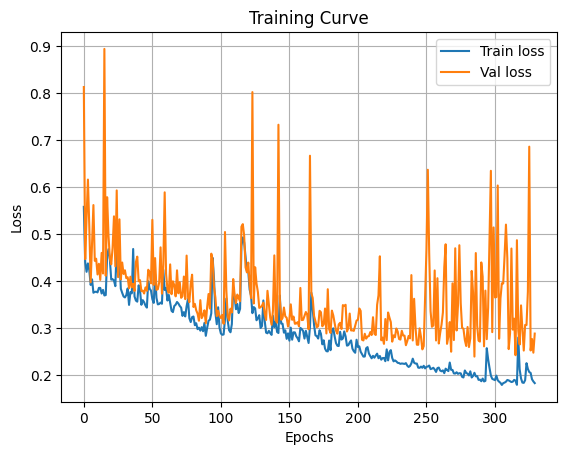

In [32]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Val loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training Curve')
plt.grid()
plt.savefig("loss.png")
plt.show()


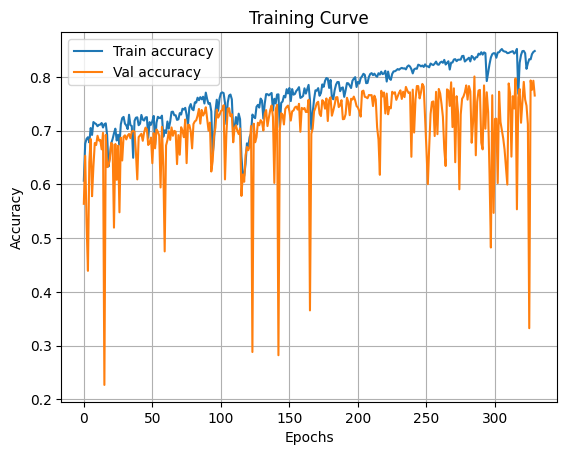

In [33]:
plt.plot(history.history['accuracy'], label='Train accuracy')
plt.plot(history.history['val_accuracy'], label='Val accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training Curve')
plt.grid()
plt.savefig("acc.png")
plt.show()

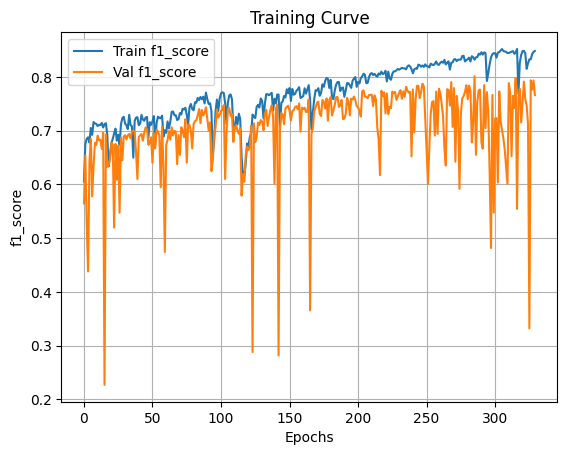

In [35]:
plt.plot(history.history['f1_score'], label='Train f1_score')
plt.plot(history.history['val_f1_score'], label='Val f1_score')
plt.xlabel('Epochs')
plt.ylabel('f1_score')
plt.legend()
plt.title('Training Curve')
plt.grid()
plt.savefig("f1_score.png")
plt.show()

44/44 ━━━━━━━━━━━━━━━━━━━━ 9s 204ms/step


/tmp/ipykernel_35/3500244442.py:59: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


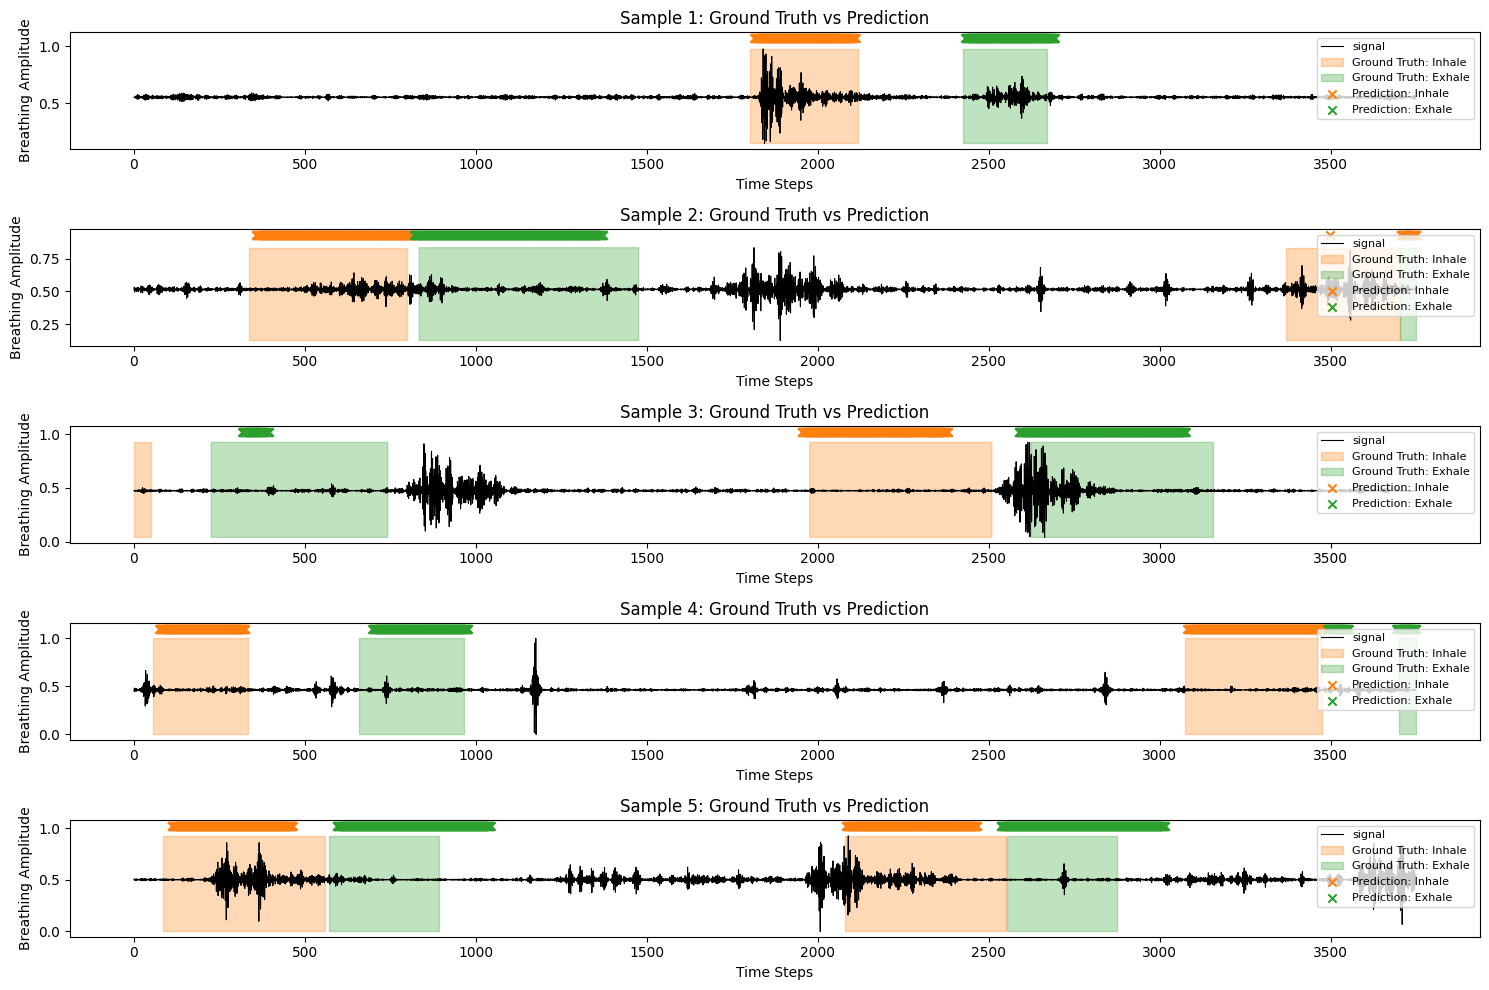

In [36]:
# Predict on the test set
predictions = model.predict(X_train)

# Convert one-hot encoded predictions and true labels back to class indices
predicted_classes = np.argmax(predictions, axis=-1)  # Shape: (num_samples, 1024)
true_classes = np.argmax(Y_train, axis=-1)  # Shape: (num_samples, 1024)

# Define class labels for visualization
class_labels = ['Background', 'Inhale', 'Exhale']  # Adjust based on your dataset

# Plot a few examples
num_examples = 5  # Number of examples to visualize
plt.figure(figsize=(15, 10))

for i in range(num_examples):
    sample_idx = i  # Select the ith sample
    plt.subplot(num_examples, 1, i + 1)

    # Plot the input ECG signal
    plt.plot(
        X_test[sample_idx, :, 0],
        label='signal',
        color='black',
        linewidth=0.8
    )

    # Highlight ground truth labels as regions
    for class_idx, label in enumerate(class_labels):
        if class_idx == 0:  # Skip background
            continue
        class_mask = (true_classes[sample_idx] == class_idx)
        plt.fill_between(
            range(3750),
            X_test[sample_idx, :, 0].min(),  # Fill from min value
            X_test[sample_idx, :, 0].max(),  # Fill to max value
            where=class_mask,
            color=f'C{class_idx}',
            alpha=0.3,
            label=f'Ground Truth: {label}'
        )

    # Overlay predicted labels as points
    for class_idx, label in enumerate(class_labels):
        if class_idx == 0:  # Skip background
            continue
        class_mask = (predicted_classes[sample_idx] == class_idx)
        plt.scatter(
            np.where(class_mask)[0],  # Time indices where the class is predicted
            [X_test[sample_idx, :, 0].max() + 0.1] * sum(class_mask),  # Offset points for visibility
            color=f'C{class_idx}',
            marker='x',
            label=f'Prediction: {label}'
        )

    plt.xlabel('Time Steps')
    plt.ylabel('Breathing Amplitude')
    plt.legend(loc='upper right', fontsize=8)
    plt.title(f'Sample {i+1}: Ground Truth vs Prediction')
    plt.tight_layout()

plt.savefig("/kaggle/working/train_data_pred.png")


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 203ms/step


/tmp/ipykernel_35/431736644.py:59: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


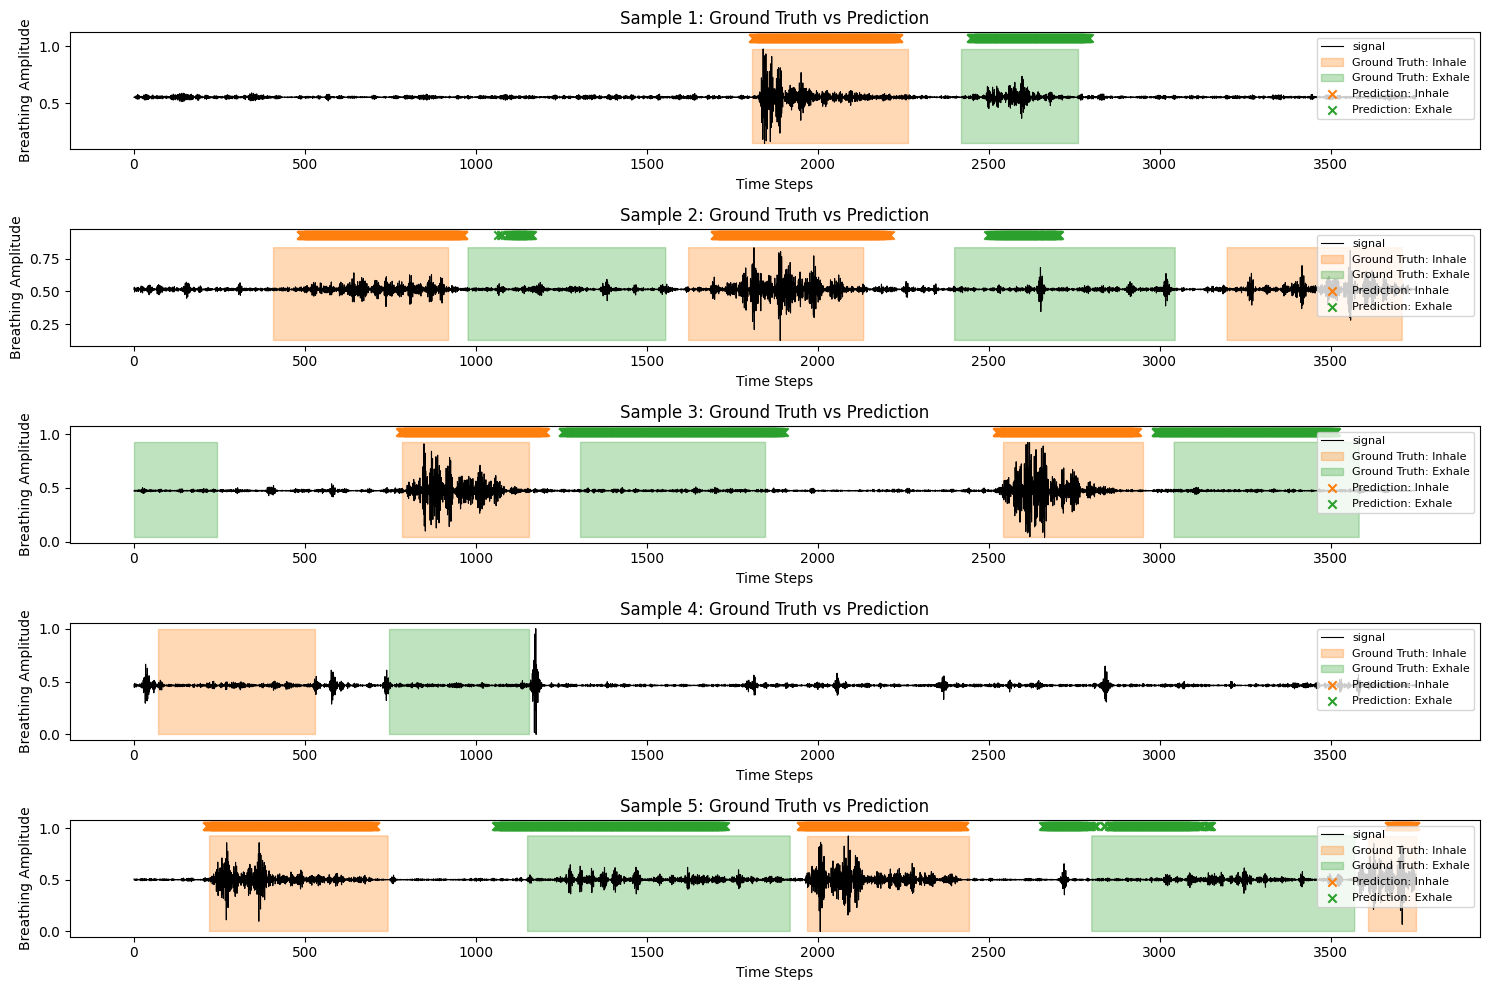

In [45]:
# Predict on the test set
predictions = model.predict(X_val)

# Convert one-hot encoded predictions and true labels back to class indices
predicted_classes = np.argmax(predictions, axis=-1)  # Shape: (num_samples, 1024)
true_classes = np.argmax(Y_val, axis=-1)  # Shape: (num_samples, 1024)

# Define class labels for visualization
class_labels = ['Background', 'Inhale', 'Exhale']  # Adjust based on your dataset

# Plot a few examples
num_examples = 5  # Number of examples to visualize
plt.figure(figsize=(15, 10))
st = 0
for i in range(st, num_examples+st):
    sample_idx = i  # Select the ith sample
    plt.subplot(num_examples, 1, i + 1-st)

    # Plot the input ECG signal
    plt.plot(
        X_test[sample_idx, :, 0],
        label='signal',
        color='black',
        linewidth=0.8
    )

    # Highlight ground truth labels as regions
    for class_idx, label in enumerate(class_labels):
        if class_idx == 0:  # Skip background
            continue
        class_mask = (true_classes[sample_idx] == class_idx)
        plt.fill_between(
            range(3750),
            X_test[sample_idx, :, 0].min(),  # Fill from min value
            X_test[sample_idx, :, 0].max(),  # Fill to max value
            where=class_mask,
            color=f'C{class_idx}',
            alpha=0.3,
            label=f'Ground Truth: {label}'
        )

    # Overlay predicted labels as points
    for class_idx, label in enumerate(class_labels):
        if class_idx == 0:  # Skip background
            continue
        class_mask = (predicted_classes[sample_idx] == class_idx)
        plt.scatter(
            np.where(class_mask)[0],  # Time indices where the class is predicted
            [X_test[sample_idx, :, 0].max() + 0.1] * sum(class_mask),  # Offset points for visibility
            color=f'C{class_idx}',
            marker='x',
            label=f'Prediction: {label}'
        )

    plt.xlabel('Time Steps')
    plt.ylabel('Breathing Amplitude')
    plt.legend(loc='upper right', fontsize=8)
    plt.title(f'Sample {i+1-st}: Ground Truth vs Prediction')
    plt.tight_layout()

plt.savefig("/kaggle/working/val_data_pred.png")
